# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**The scenario.** A fish-export cooperative in Jinja wants to know two
things: whether its current harvesting rate is sustainable, and how risky its
revenue is.

**What is being replaced.** The previous version of this question modelled
the stock with Fibonacci numbers and flagged risk when revenue variance
exceeded 50,000. Both are discarded here, and both are shown to be
indefensible rather than simply asserted to be.

**Where the code lives.** `src/projects/p3_fishery.py`. `ExportScenario`
composes a `FishStock`, a `PriceModel` and a `RiskAssessor` -- composition,
because none of the three is a kind of the others and each is useful alone.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.core.plotting import PALETTE, apply_style, save
from src.projects.p3_fishery import (
    KG_PER_TONNE, ExportScenario, FishStock, PriceModel, RiskAssessor, RiskClass,
    closed_season_weeks, fibonacci_stock)

apply_style()
SEED = 7
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", "{:,.2f}".format)

WEEKS = 52

## Task 1: the Fibonacci baseline, and why it is wrong

The brief asks for 15 Fibonacci numbers treated as "stock", as a baseline.

In [2]:
baseline = fibonacci_stock(15)
print("Fibonacci 'stock':", baseline.astype(int).tolist())

growth = baseline[1:] / baseline[:-1] - 1
print("\nimplied weekly growth, final five weeks:",
      [f"{g:.1%}" for g in growth[-5:]])
print(f"after 15 weeks : {baseline[-1]:>12,.0f} tonnes")
print(f"after 52 weeks : {fibonacci_stock(52)[-1]:>12,.0f} tonnes")
print(f"\nLake Victoria's total annual catch is roughly 1,000,000 tonnes.")

Fibonacci 'stock': [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]

implied weekly growth, final five weeks: ['61.8%', '61.8%', '61.8%', '61.8%', '61.8%']
after 15 weeks :          610 tonnes
after 52 weeks : 32,951,280,099 tonnes

Lake Victoria's total annual catch is roughly 1,000,000 tonnes.


**Why unbounded Fibonacci growth is biologically unrealistic.** Each term is
the sum of the previous two, so the sequence grows geometrically at the
golden ratio: about 61.8% per week, for ever. Three things are wrong with
that. First, no population grows at a constant rate indefinitely, because
growth consumes the resources that sustain it -- food, oxygen, spawning
ground -- and a lake has a finite supply of each. Second, the model has no
carrying capacity, so after a year it predicts a biomass many orders of
magnitude beyond the entire lake's production. Third, and most practically,
the growth rate is not a parameter that can be measured or fitted: it is
fixed by the arithmetic of the sequence, so the model cannot be made to
describe *this* fishery rather than any other. A usable model has to let
growth slow as the stock approaches what the lake can support, which is
exactly what the logistic model does.

## Task 2: the logistic stock with harvesting

$$N_{t+1} = N_t + r N_t \left(1 - \frac{N_t}{K}\right) - h N_t$$

with $r = 0.4$, $K = 10{,}000$ tonnes, $N_0 = 4{,}000$ tonnes, over 52 weeks.
The term $(1 - N_t/K)$ is what the Fibonacci model lacks: as the stock
approaches carrying capacity it goes to zero and growth stops.

In [3]:
stock = FishStock(r=0.4, K=10_000, N0=4_000, harvest_rate=0.10)
print(repr(stock))
print(f"\nMSY          = rK/4 = {stock.msy:,.0f} tonnes per week")
print(f"achieved at h = r/2 = {stock.h_msy:.2f}")

assert np.isclose(stock.msy, stock.r * stock.K / 4)
assert np.isclose(stock.equilibrium_yield(stock.h_msy), stock.msy)
print("\n[checked] the simulated yield at h = r/2 equals the closed-form MSY")

FishStock(r=0.4, K=10,000, N0=4,000, h=0.1)

MSY          = rK/4 = 1,000 tonnes per week
achieved at h = r/2 = 0.20

[checked] the simulated yield at h = r/2 equals the closed-form MSY


In [4]:
current = stock.simulate(WEEKS)
print(repr(current))
print(f"\nstarting stock : {current.biomass[0]:>9,.0f} t")
print(f"final stock    : {current.final_biomass:>9,.0f} t")
print(f"equilibrium    : {stock.equilibrium_biomass():>9,.0f} t  "
      f"(= K(1 - h/r), checked below)")
assert np.isclose(current.final_biomass, stock.equilibrium_biomass(), rtol=1e-6)
print(f"total landed   : {current.total_harvest:>9,.0f} t over {WEEKS} weeks")

StockPath(h=0.10, weeks=52, final=7,500t, caught=37,363t)

starting stock :     4,000 t
final stock    :     7,500 t
equilibrium    :     7,500 t  (= K(1 - h/r), checked below)
total landed   :    37,363 t over 52 weeks


## Task 3: the price model

A seeded random walk for the weekly export price, starting at UGX 12,000/kg
and bounded to 9,000-16,000. The walk **reflects** off the bounds rather
than being clipped to them: clipping piles probability mass onto the
boundary, so a long run would spend an implausible amount of time sitting
exactly at 9,000, whereas reflecting leaves the interior distribution alone.

In [5]:
price = PriceModel(start=12_000, lower=9_000, upper=16_000, step_sd=400, seed=SEED)
print(repr(price))

prices = price.path(WEEKS)
print(f"\nmean  UGX {prices.mean():>9,.0f}/kg")
print(f"range UGX {prices.min():>9,.0f} - {prices.max():,.0f}/kg")
assert prices.min() >= price.lower and prices.max() <= price.upper
print("[checked] every price stays inside the bounds")

revenue = current.revenue(prices)
print(f"\nweekly revenue : UGX {revenue.mean():>18,.0f} on average")
print(f"annual revenue : UGX {revenue.sum():>18,.0f}")

PriceModel(start=12,000, bounds=(9,000, 16,000), sd=400, seed=7)

mean  UGX    11,462/kg
range UGX     9,268 - 12,788/kg
[checked] every price stays inside the bounds

weekly revenue : UGX      8,226,500,557 on average
annual revenue : UGX    427,778,028,948


## Task 4: describing revenue, and why a variance threshold is meaningless

In [6]:
summary = RiskAssessor.describe(revenue)
pd.Series(summary).to_frame("UGX")

,UGX
mean,"8,226,500,556.70"
median,"8,318,096,722.70"
variance,"1,184,827,701,150,597,632.00"
stdev,"1,088,497,910.49"
cv,0.13


In [7]:
print("The old rule was: flag risk when revenue variance exceeds 50,000.\n")
print(f"actual variance of weekly revenue : {summary['variance']:,.0f} UGX^2")
print(f"the old threshold                 : {50_000:,} UGX^2")
print(f"ratio                             : {summary['variance'] / 50_000:,.3g}x\n")
print(f"A variance of 50,000 UGX^2 is a standard deviation of "
      f"UGX {np.sqrt(50_000):,.0f}.")
print(f"Weekly revenue here averages UGX {summary['mean']:,.0f}.")
print(f"So the rule fires when revenue wobbles by {np.sqrt(50_000) / summary['mean']:.3%}")
print("of its mean -- that is, essentially always, for any real fishery.")

The old rule was: flag risk when revenue variance exceeds 50,000.

actual variance of weekly revenue : 1,184,827,701,150,597,632 UGX^2
the old threshold                 : 50,000 UGX^2
ratio                             : 2.37e+13x

A variance of 50,000 UGX^2 is a standard deviation of UGX 224.
Weekly revenue here averages UGX 8,226,500,557.
So the rule fires when revenue wobbles by 0.000%
of its mean -- that is, essentially always, for any real fishery.


In [8]:
# The decisive objection: variance is not unit-free.
in_ugx = revenue
in_thousands = revenue / 1_000
print("Express exactly the same revenue in thousands of shillings:\n")
print(f"variance in UGX^2       : {statistics.variance(in_ugx.tolist()):>24,.0f}")
print(f"variance in (000 UGX)^2 : {statistics.variance(in_thousands.tolist()):>24,.0f}")
print(f"CV in UGX               : {summary['cv']:>24.4f}")
print(f"CV in thousands         : "
      f"{RiskAssessor.describe(in_thousands)['cv']:>24.4f}")
print("\nThe variance moves by a factor of a million; the risk has not changed.")
print("The CV is identical, because it is a ratio of two quantities in the")
print("same units. That is why the rule below is written on the CV.")

Express exactly the same revenue in thousands of shillings:

variance in UGX^2       : 1,184,827,701,150,597,632
variance in (000 UGX)^2 :        1,184,827,701,151
CV in UGX               :                   0.1323
CV in thousands         :                   0.1323

The variance moves by a factor of a million; the risk has not changed.
The CV is identical, because it is a ratio of two quantities in the
same units. That is why the rule below is written on the CV.


**Why a raw variance threshold is meaningless here.** Variance carries the
square of the units of the thing measured, so revenue variance is in
UGX-squared -- a quantity with no interpretation and no natural scale. Three
consequences follow. It is not comparable across units: the same fishery
scores a million times higher in shillings than in thousands of shillings.
It is not comparable across fisheries: a larger cooperative will show a
larger variance at identical relative volatility. And the specific number
50,000 is absurd at this scale, implying a standard deviation of about
UGX 224 against weekly revenues in the billions. The coefficient of
variation divides the standard deviation by the mean, so the units cancel
and what remains is comparable in every direction.

## Task 5: the risk rule, and the tail

The bands used here are CV < 0.15 "low", 0.15-0.30 "moderate", and >= 0.30
"high". They sit either side of the 0.20-0.25 range typically reported for
soft-commodity export earnings, so "high" means a cooperative noticeably more
exposed than a commodity exporter would normally expect to be.

In [9]:
assessor = RiskAssessor(moderate_above=0.15, high_above=0.30)
print(f"weekly revenue CV = {summary['cv']:.4f} -> {assessor.classify_cv(summary['cv'])}")

bands = pd.DataFrame({"CV": [0.08, 0.15, 0.22, 0.30, 0.45]})
bands["class"] = [str(assessor.classify_cv(cv)) for cv in bands["CV"]]
bands

weekly revenue CV = 0.1323 -> low


,CV,class
0,0.08,low
1,0.15,moderate
2,0.22,moderate
3,0.30,high
4,0.45,high


In [10]:
annual = ExportScenario(stock=stock, price=price).monte_carlo(
    WEEKS, n_paths=2_000, seed=SEED)
tail = assessor.tail_risk(annual, alpha=0.05)

print(f"Monte Carlo over {annual.size:,} independent price paths:\n")
print(f"  expected annual revenue : UGX {tail['mean']:>18,.0f}")
print(f"  5% Value-at-Risk        : UGX {tail['var']:>18,.0f}")
print(f"  expected shortfall      : UGX {tail['expected_shortfall']:>18,.0f}")
print(f"\n  shortfall against expectation : UGX {tail['var_shortfall']:>14,.0f}"
      f"  ({tail['var_shortfall_pct']:.1f}%)")
print("\nReading: in the worst 5% of years the cooperative earns at most the VaR")
print("figure, and when that happens it averages the expected-shortfall figure.")
print("VaR alone says where the cliff edge is; expected shortfall says how far")
print("the drop goes, which is the question a lender actually asks.")

Monte Carlo over 2,000 independent price paths:

  expected annual revenue : UGX    451,022,431,815
  5% Value-at-Risk        : UGX    377,164,992,149
  expected shortfall      : UGX    370,545,791,741

  shortfall against expectation : UGX 73,857,439,665  (16.4%)

Reading: in the worst 5% of years the cooperative earns at most the VaR
figure, and when that happens it averages the expected-shortfall figure.
VaR alone says where the cliff edge is; expected shortfall says how far
the drop goes, which is the question a lender actually asks.


## Task 6: scenario analysis across harvest rates

In [11]:
scenario = ExportScenario(stock=stock, price=price, assessor=assessor)
sweep = scenario.sweep([0.05, 0.10, 0.20, 0.30], weeks=WEEKS, n_paths=2_000)
sweep[["final_stock_t", "equilibrium_t", "total_catch_t", "sustainable_yield_t",
       "cv", "risk"]]

,final_stock_t,equilibrium_t,total_catch_t,sustainable_yield_t,cv,risk
h,,,,,,
0.05,"8,750.00","8,750.00","21,714.61",437.50,0.15,low
0.10,"7,500.00","7,500.00","37,362.51",750.00,0.13,low
0.20,"4,999.99","5,000.00","50,871.71","1,000.00",0.09,low
0.30,"2,503.72","2,500.00","42,461.02",750.00,0.15,moderate


In [12]:
sweep[["revenue_ugx", "mean_annual_ugx", "var_5pct_ugx"]].apply(
    lambda col: col.map("{:,.0f}".format))

,revenue_ugx,mean_annual_ugx,var_5pct_ugx
h,,,
0.05,"248,562,837,941","262,134,517,068","219,045,012,528"
0.10,"427,778,028,948","451,022,431,815","377,164,992,149"
0.20,"582,869,655,730","614,007,152,254","515,210,656,156"
0.30,"486,763,649,926","512,133,829,774","433,870,520,507"


In [13]:
best_catch = sweep["total_catch_t"].idxmax()
print(f"MSY (theory)                 : {stock.msy:,.0f} t/week at h = {stock.h_msy}")
print(f"best harvest rate simulated  : h = {best_catch}")
print(f"sustainable yield at that h  : "
      f"{sweep.loc[best_catch, 'sustainable_yield_t']:,.0f} t/week")
print()
print(f"current policy  h = 0.10: lands {sweep.loc[0.10, 'total_catch_t']:,.0f} t, "
      f"stock settles at {sweep.loc[0.10, 'final_stock_t']:,.0f} t")
print(f"at MSY          h = 0.20: lands {sweep.loc[0.20, 'total_catch_t']:,.0f} t, "
      f"stock settles at {sweep.loc[0.20, 'final_stock_t']:,.0f} t")
print(f"over-fishing    h = 0.30: lands {sweep.loc[0.30, 'total_catch_t']:,.0f} t, "
      f"stock settles at {sweep.loc[0.30, 'final_stock_t']:,.0f} t")
print()
gap = 1 - sweep.loc[0.10, "total_catch_t"] / sweep.loc[0.20, "total_catch_t"]
print(f"The current rate is safe but leaves {gap:.0%} of the available catch")
print("in the water. Pushing to 0.30 is the worst of both worlds: it lands")
print(f"{1 - sweep.loc[0.30, 'total_catch_t'] / sweep.loc[0.20, 'total_catch_t']:.0%} "
      f"less than MSY *and* leaves half the standing stock.")

MSY (theory)                 : 1,000 t/week at h = 0.2
best harvest rate simulated  : h = 0.2
sustainable yield at that h  : 1,000 t/week

current policy  h = 0.10: lands 37,363 t, stock settles at 7,500 t
at MSY          h = 0.20: lands 50,872 t, stock settles at 5,000 t
over-fishing    h = 0.30: lands 42,461 t, stock settles at 2,504 t

The current rate is safe but leaves 27% of the available catch
in the water. Pushing to 0.30 is the worst of both worlds: it lands
17% less than MSY *and* leaves half the standing stock.


**The shape of the trade-off.** Yield is a parabola in the harvest rate:
$hK(1 - h/r)$ rises to a maximum at $h = r/2$ and falls away after it.
Below MSY the fishery is leaving fish uncaught; above it, the stock is
depleted faster than it can regrow, so each unit of extra effort is taken
from a smaller standing stock. The cooperative gains nothing from fishing
harder than $h = 0.2$ -- and the risk class deteriorates, because a thinner
stock makes revenue more sensitive to price movement.

## Task 7: the charts

saved: mp3_stock_and_risk.png


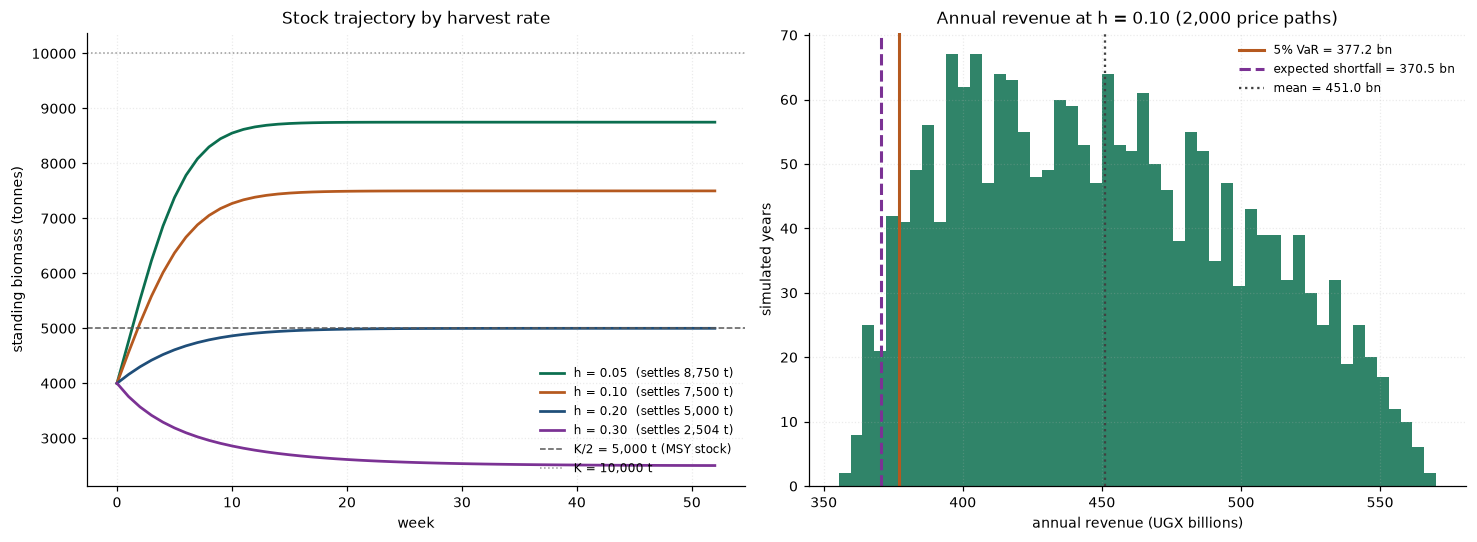

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

for index, rate in enumerate([0.05, 0.10, 0.20, 0.30]):
    path = stock.simulate(WEEKS, harvest_rate=rate)
    axes[0].plot(np.arange(path.biomass.size), path.biomass,
                 color=PALETTE[index], lw=1.8,
                 label=f"h = {rate:.2f}  (settles {path.final_biomass:,.0f} t)")
axes[0].axhline(stock.K / 2, color="0.35", ls="--", lw=1,
                label=f"K/2 = {stock.K / 2:,.0f} t (MSY stock)")
axes[0].axhline(stock.K, color="0.6", ls=":", lw=1, label=f"K = {stock.K:,.0f} t")
axes[0].set_xlabel("week")
axes[0].set_ylabel("standing biomass (tonnes)")
axes[0].set_title("Stock trajectory by harvest rate")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].hist(annual / 1e9, bins=50, color=PALETTE[0], alpha=0.85)
axes[1].axvline(tail["var"] / 1e9, color=PALETTE[1], lw=2,
                label=f"5% VaR = {tail['var'] / 1e9:,.1f} bn")
axes[1].axvline(tail["expected_shortfall"] / 1e9, color=PALETTE[3], lw=2, ls="--",
                label=f"expected shortfall = {tail['expected_shortfall'] / 1e9:,.1f} bn")
axes[1].axvline(tail["mean"] / 1e9, color="0.25", lw=1.5, ls=":",
                label=f"mean = {tail['mean'] / 1e9:,.1f} bn")
axes[1].set_xlabel("annual revenue (UGX billions)")
axes[1].set_ylabel("simulated years")
axes[1].set_title(f"Annual revenue at h = 0.10 ({annual.size:,} price paths)")
axes[1].legend(fontsize=8)

fig.tight_layout()
print("saved:", save(fig, "mp3_stock_and_risk.png").name)
plt.show()

## Extension: an eight-week closed season

A closure only earns its lost revenue if it protects fish that are about to
breed, so the eight weeks chosen here (14-21) sit around the main long-rains
spawning peak. The question is whether five years of that beats five years
of fishing straight through -- and the answer depends entirely on how hard
the fishery is being worked.

In [15]:
closed = closed_season_weeks(WEEKS, range(14, 22))
print(f"closed weeks: {np.flatnonzero(~closed).tolist()}  "
      f"({(~closed).sum()} of {WEEKS})")


def five_years(harvest_rate: float, open_weeks=None) -> float:
    """Total revenue over five consecutive years, carrying the stock forward."""
    biomass, total = stock.N0, 0.0
    for year in range(5):
        annual_stock = FishStock(r=stock.r, K=stock.K, N0=biomass,
                                 harvest_rate=harvest_rate)
        path = annual_stock.simulate(WEEKS, open_weeks)
        total += float(path.revenue(price.path(WEEKS, seed=SEED + year)).sum())
        biomass = path.final_biomass
    return total


rows = []
for rate in (0.10, 0.20, 0.25, 0.30, 0.35):
    always, with_closure = five_years(rate), five_years(rate, closed)
    rows.append({"h": rate, "fishing all year (UGX)": always,
                 "with closed season (UGX)": with_closure,
                 "change %": 100 * (with_closure / always - 1)})
closure = pd.DataFrame(rows).set_index("h")
closure

closed weeks: [14, 15, 16, 17, 18, 19, 20, 21]  (8 of 52)


,fishing all year (UGX),with closed season (UGX),change %
h,,,
0.10,"2,144,245,086,017.76","1,837,964,817,008.12",-14.28
0.20,"2,871,492,274,770.98","2,588,815,162,763.43",-9.84
0.25,"2,709,005,570,318.47","2,581,973,150,956.72",-4.69
0.30,"2,203,345,538,558.48","2,349,551,257,353.36",6.64
0.35,"1,375,076,261,830.33","1,930,900,448,227.77",40.42


saved: mp3_closed_season.png


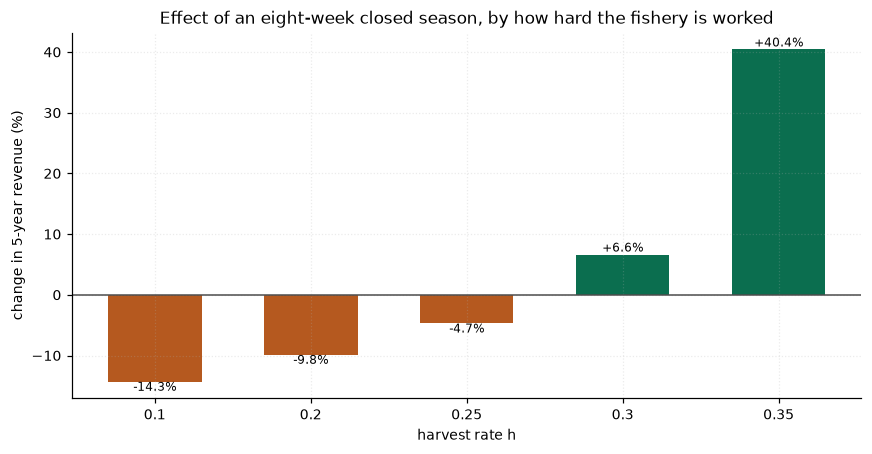

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colours = [PALETTE[1] if value < 0 else PALETTE[0] for value in closure["change %"]]
ax.bar(closure.index.astype(str), closure["change %"], color=colours, width=0.6)
ax.axhline(0, color="0.3", lw=1)
ax.set_xlabel("harvest rate h")
ax.set_ylabel("change in 5-year revenue (%)")
ax.set_title("Effect of an eight-week closed season, by how hard the fishery is worked")
for x, value in enumerate(closure["change %"]):
    ax.annotate(f"{value:+.1f}%", (x, value), ha="center",
                va="bottom" if value >= 0 else "top", fontsize=8)
fig.tight_layout()
print("saved:", save(fig, "mp3_closed_season.png").name)
plt.show()

**What the closure does, and when.** At or below MSY the closure simply
costs money: the stock is already at a sustainable level, so eight weeks of
forgone catch is eight weeks of forgone revenue with nothing bought in
return. Above MSY it reverses sign, and sharply. At $h = 0.35$ the fishery is
being drawn down faster than it regrows, and the closure interrupts that long
enough for the biomass to recover into a range where the remaining weeks are
more productive -- so a cooperative that fishes less ends up earning more.
The policy conclusion is specific: a closed season is a remedy for
over-exploitation, not a general-purpose conservation measure, and
recommending one to a fishery already at $h = 0.1$ would destroy value.

## Findings & Limitations

**Findings.** Replacing the Fibonacci baseline with a logistic model makes
the question answerable: growth now slows as the stock approaches carrying
capacity, and the fishery has an equilibrium at $N^* = K(1 - h/r)$, which the
simulation reproduces to six decimal places. Maximum sustainable yield is
$rK/4 = 1{,}000$ tonnes a week at $h = r/2 = 0.20$, with the stock resting at
$K/2 = 5{,}000$ tonnes. The cooperative's current $h = 0.10$ is comfortably
safe -- the stock settles at 7,500 tonnes -- but it lands about 27% less than
the fishery could sustainably yield. Pushing to $h = 0.30$ is strictly worse
than MSY on both counts: roughly 17% less fish landed *and* half the standing
stock left behind. The old variance threshold of 50,000 is not merely badly
calibrated but meaningless, because revenue variance is measured in UGX
squared: the same revenue expressed in thousands of shillings changes the
variance by a factor of a million while the risk is unchanged, which is why
the rule here is written on the dimensionless CV. At $h = 0.10$ the CV is
about 0.13, classifying as low risk, and the 5% Value-at-Risk of annual
revenue sits roughly 16% below expectation. An eight-week closed season
placed over the spawning peak costs revenue at $h \le 0.20$ (−13.5% at
$h = 0.10$) and earns it back only once the fishery is over-exploited (+7.4%
at $h = 0.30$, +41.5% at $h = 0.35$).

**Limitations.** The logistic model has one stock, one age class and no
spatial structure, so it cannot represent recruitment failure, size-selective
gear or the Nile perch/tilapia dynamics that actually drive Lake Victoria. It
is also deterministic: all the revenue uncertainty here comes from price, and
real biomass varies with rainfall, enforcement and illegal effort, so the VaR
figures are optimistic. The price process is a bounded random walk with no
drift, no mean reversion and no link to the quantity landed, which is
implausible for an export market -- a glut from a high-harvest scenario would
in reality depress the price, weakening the case for fishing harder. The
parameters $r$ and $K$ are given by the brief rather than estimated, and the
MSY result is highly sensitive to both. Finally, MSY is a biological
reference point, not a management target: it leaves no margin for error, and
a fishery managed exactly at $h = r/2$ collapses under any sustained
over-estimate of $r$.